***
Welcome! 

In this session we are going to build our  model and classify some text based on its sentiment.
We will use a tagged corpus of Movie Reviews to train our model and classify unseen examples, trying to predict if a movie review is positive or negative.

We will rely on the scikit-learn library that has some relevant implementation of a Logistic Regression, the first technique we will use to classify our text. Also, we'll test with `NaiveBayes`, another type of classifier.
<br>
We will also talk about how we can create features that represent our text.
***

### Index:

[1.1 - Loading the Data](#1.1---Loading-the-Data)
<br>
[1.2 - Pre-process Text](#1.2---Pre-process-Text)
<br>
[1.3 - Log Ratio of Words](#1.3---Log-Ratio-of-Words)
<br>
[1.4 - Vectorizing Sentences (Text Representation)](#1.4---Vectorizing-Sentences-(Text-Representation))
<br>
[2 - Training Model](#2---Training-Model)



In [1]:
# NLTK Stands for Natural Language Toolkit
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from nltk.tokenize import word_tokenize
import spacy

# Import OS Library
import os

# Import string library
import string

# Import pandas
import pandas as pd
# Supress warnings
pd.options.mode.chained_assignment = None 

# Import numpy
import numpy as np

# Supress scientific notation
pd.set_option('display.float_format', '{:.2f}'.format)
np.set_printoptions(suppress=True, formatter={'float_kind':'{:0.2f}'.format})


# Import math
import math

# Import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.feature_extraction.text import (
    CountVectorizer
)

import warnings
warnings.filterwarnings('ignore')

## 1 - Preparing Features

### 1.1 - Loading the Data

First, we will load 1000 positive reviews and 1000 negative reviews:

In [2]:
neg_files = os.listdir('data/neg')
pos_files = os.listdir('data/pos')

In [3]:
def get_reviews(directory, file_list):
    files=[]
    for file in file_list:
        f = open('data/'+directory+'/'+file, "r")
        #append each line in the file to a list
        files.append(f.read())
        f.close()
        
    return files

In [4]:
negative_files = get_reviews('neg', neg_files)
positive_files = get_reviews('pos', pos_files)

Let's see some examples of some negative reviews:

In [5]:
print(negative_files[1])

isn't it the ultimate sign of a movie's cinematic ineptitude when you can't think of much to say about it other than " it sucks " ? 
one of the first official year 2000 releases , supernova is such a movie . 
i can't seem to get past one-word adjectives with this one , although " boring , " " stupid " and " absurd " doesn't amount to much of a review . 
a shame . 
i would have been able to save myself the chore of desperately trying to elaborate . 
but c'est la vie . 
here goes nothing . 
i'll keep it short . 
i suppose the first bad omen for supernova came when director walter hill ( 48 hours ) removed his name from the movie , requesting that it be replaced with the pseudonym thomas lee . 
the film's fate was sealed in many minds when struggling studio mgm declined to screen it for the press , an event usually signifying a studio's lack of confidence in a particular movie . 
hill's and mgm's actions were prudent . 
when the captain of medical space vessel nightingale dies in a tragic

In [6]:
print(negative_files[2])

 " gordy " is not a movie , it is a 90-minute-long " sesame street " skit , and a very bad one at that . 
this movie is so stupid and dumb that it's depressing to think that some hollywood executives actually gave this the green light , and even more surprising is the fact that this is a disney movie . 
i'm sure children are the target audience of this movie , but only kids under the age of five may be able to tolerate it . 
it is the story of a farm a piglet named gordy ( voiced by garms ) , whose family has been taken away to " up north , " which we know means death . 
of course we can hear the animals talk to each other , and they actually went to the trouble of attempting to sync the voices with their mouths but it comes out terrible . 
actually , it's almost funny in a way . 
the only remotely interesting and likable character soon appears , a little girl named jinnie sue macallister ( young ) who sees gordy on the back of a truck and essentially steals him . 
jinnie is a country 

And some positive ones:

In [7]:
print(positive_files[2])

i actually am a fan of the original 1961 or so live-action-disney flick of the same name starring hayley mills twice as a pair of twins , separated at birth by divorcing parents , never to come in contact with the other so the parents never have to meet again . 
and everyone should know how i feel about remakes , especially of films i happen to enjoy ( my fallacy : unless you're going to either capture the same exact spirit of the original or do something different with it or maybe even both , just wrack your brain and come up with a * gasp * new idea ) . 
this remake was not originally on the top of my viewing list , and was actually quite the opposite . 
contemporary live-action-disney films are not one of my favorties , anyway : they're usually unfunny , alienating , and a big fat bore , at least to anyone over the age of 11 and above the iq of 10 . 
this one , however , is shockingly not bad . 
in fact , it's actually good . 
not the original good , but what's great about it is tha

In [8]:
print(positive_files[1])

plot : derek zoolander is a male model . 
he is also very dumb and impressionable . 
for that reason , he is secretly hired and trained ( so secret , that even he doesn't know about it ) by an underground fashion syndicate to assassinate the prime minister of malaysia , who wants to abolish child labor in his country . 
will zoolander fulfill the dirty deed ? 
will zoolander ever grace the world his new " look " ? 
is this a funny movie ? 
find out below . . . 
critique : there's a place in our world for " stupid comedies " . 
films which don't pretend to take themselves seriously , are based on idiotic premises and filled with dumb jokes . 
there's also a time for them and many would argue that this difficult period of our history , might be an ideal circumstance during which to " relax " by watching something so completely frivolous . 
well , if you're in the mood for some seriously mindless entertainment , ben stiller and his cast of many have assembled one of the more original dumb

We know, beforehand that these are positive and negative reviews. The goal of the algorithm that we will develop is to classify **new reviews** with a certain probability of being positive / negative.

### 1.2 - Pre-process Text

As we've learned, it's relevant to pre-process our text with some of the techniques we've learned so far. Here's the pipeline that we will develop before doing any vectorization:
* Lowercase text.
* Remove punctuation
* Tokenize our reviews.
* Remove stop words.
* Stem our words.

In [9]:
positive_files =[file.lower() for file in positive_files]
negative_files =[file.lower() for file in negative_files]

Let's build a function that removes the punctuation from our text:

In [10]:
def remove_punct(list_of_text):
    
    no_punct = []
    
    for index, file in enumerate(list_of_text):
        file = (
            file.translate(
                str.maketrans('', '', string.punctuation)
            )
        )

        no_punct.append(file)
    return no_punct

In [11]:
positive_files = remove_punct(positive_files)
negative_files = remove_punct(negative_files)

Removing the stop words:

In [12]:
stop_words = stopwords.words('english')

In [13]:
stop_words[1:10]

['about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']

In [14]:
positive_files_tokenized = [word_tokenize(file) for file in positive_files]
negative_files_tokenized = [word_tokenize(file) for file in negative_files]

In [15]:
def remove_stop_words(tokenized_text):
    '''
    Removes stop words from the input tokenized text.
    The input tokenized text is passed in list format.
    '''
    stop_words = stopwords.words('english')
    
    list_files_no_stop = []
    
    for file in tokenized_text:
        no_stop_words = []
        for word in file:
            if word not in stop_words:
                no_stop_words.append(word)
        
        list_files_no_stop.append(
            no_stop_words
        )
        
    return list_files_no_stop

In [16]:
positive_files_tokenized = remove_stop_words(positive_files_tokenized)
negative_files_tokenized = remove_stop_words(negative_files_tokenized)

Before stemming, let's do some analytics on our positive and negative reviews by calculating the log ratio of most common words in positive and negative reviews. This is a common metric that people use to analyze the importance of certain features when classifying text.

In [17]:
# Let's flat our list into words:
flat_list_positive = [
    item for sublist in positive_files_tokenized for item in sublist
]

In [18]:
print('We have {} words in our positive files - {} are distinct'
      .format(len(flat_list_positive), len(set(flat_list_positive))))

We have 375030 words in our positive files - 34782 are distinct


In [19]:
# Let's flat our list into words:
flat_list_negative = [
    item for sublist in negative_files_tokenized for item in sublist
]

In [20]:
print('We have {} words in our positive files - {} are distinct'
      .format(len(flat_list_negative), len(set(flat_list_negative))))

We have 335151 words in our positive files - 32595 are distinct


### 1.3 - Log Ratio of Words

We can rely on Freq Dist to check the most relevant words for positive and negative reviews:

In [21]:
nltk.FreqDist(flat_list_negative).most_common(20)

[('film', 3994),
 ('movie', 3048),
 ('one', 2617),
 ('like', 1835),
 ('even', 1381),
 ('good', 1127),
 ('time', 1112),
 ('would', 1049),
 ('get', 1037),
 ('bad', 1019),
 ('much', 997),
 ('characters', 909),
 ('films', 903),
 ('story', 903),
 ('character', 893),
 ('plot', 876),
 ('two', 865),
 ('make', 818),
 ('first', 805),
 ('really', 787)]

In [22]:
nltk.FreqDist(flat_list_positive).most_common(20)

[('film', 4866),
 ('one', 2904),
 ('movie', 2392),
 ('like', 1718),
 ('story', 1215),
 ('also', 1200),
 ('films', 1199),
 ('good', 1193),
 ('even', 1174),
 ('time', 1171),
 ('characters', 1038),
 ('much', 1027),
 ('character', 1013),
 ('would', 993),
 ('life', 984),
 ('well', 968),
 ('first', 963),
 ('two', 960),
 ('see', 954),
 ('way', 915)]

In [23]:
negative_freq = pd.DataFrame(
    nltk.FreqDist(flat_list_negative).values(), 
    index=nltk.FreqDist(flat_list_negative).keys(),
    columns=['word_count_negative']
)
positive_freq = pd.DataFrame(
    nltk.FreqDist(flat_list_positive).values(), 
    index=nltk.FreqDist(flat_list_positive).keys(),
    columns=['word_count_positive']
)

In [24]:
word_sentiment = negative_freq.join(positive_freq).fillna(0)

Let's calculate the Log Ratio between Positive and Negative Words

In [25]:
word_sentiment['ratio'] = (
    np.log(
        word_sentiment.word_count_positive
        /word_sentiment.word_count_negative
    )
)

We can now check which words are more relevant for positive and negative reviews. Top words for negative reviews are:

In [26]:
word_sentiment.loc[
    word_sentiment.word_count_negative + word_sentiment.word_count_positive > 100 
].sort_values(by='ratio').head(10)

,word_count_negative,word_count_positive,ratio
godzilla,116,14.00,-2.11
wasted,101,16.00,-1.84
lame,90,15.00,-1.79
waste,121,22.00,-1.70
worst,259,48.00,-1.69
ridiculous,117,22.00,-1.67
awful,109,21.00,-1.65
stupid,207,44.00,-1.55
dull,110,24.00,-1.52
boring,217,52.00,-1.43


In [27]:
word_sentiment.loc[
    word_sentiment.word_count_negative + word_sentiment.word_count_positive > 100 
].sort_values(by='ratio').tail(10)

,word_count_negative,word_count_positive,ratio
excellent,37,146.00,1.37
political,31,123.00,1.38
terrific,24,96.00,1.39
memorable,29,117.00,1.39
pulp,21,86.00,1.41
jackie,47,209.00,1.49
cameron,22,106.00,1.57
toy,17,87.00,1.63
titanic,18,105.00,1.76
truman,11,121.00,2.40


### 1.4 - Vectorizing Sentences (Text Representation)

In this part of the notebook, we'll do two versions of text representation: 
* Representing our text with a CountVectorizer using the `stems` of the original tokens.
* Representing our words as the average of the word vectors (using `spacy`). In this case, we will not stem the tokens.

These two concurrent approaches will be used to train our algorithm.

Let's start by doing the CountVectorizer of the stems:

In [28]:
def stem_sentence(tokenized_sentence):
    stemmer = PorterStemmer()
    stem_sentence = []
    for word in tokenized_sentence:
        stem_sentence.append(stemmer.stem(word))
        
    return stem_sentence

stemmed_negative_files = [
    stem_sentence(sentence) for sentence in negative_files_tokenized
]
stemmed_positive_files = [
    stem_sentence(sentence) for sentence in positive_files_tokenized
]

sentence_negative = [' '.join(file) for file in stemmed_negative_files]
sentence_positive = [' '.join(file) for file in stemmed_positive_files]

sentence_negative = pd.DataFrame(sentence_negative, columns=['sentence'])
sentence_positive = pd.DataFrame(sentence_positive, columns=['sentence'])

In [29]:
sentence_positive.head(10)

,sentence
0,assum noth phrase perhap one use 1990 first im...
1,plot derek zooland male model also dumb impres...
2,actual fan origin 1961 liveactiondisney flick ...
3,movi that highli built truman show review boas...
4,good hunt two movi one independ take struggl f...
5,stori us rob reiner film second movi fall touc...
6,anastasia contain someth lack recent disney re...
7,fight sullivan contain major plot develop last...
8,georg littl jonathan lipnicki want littl broth...
9,read review got ta know love woodi allen impor...


Creating the full vectorizer of positive and negative sentences:

In [30]:
training_base = pd.concat([sentence_positive, sentence_negative], ignore_index=True)

cv = CountVectorizer(binary=True)
X = cv.fit_transform(training_base.sentence).todense()
X = pd.DataFrame(
    X,
    columns=cv.get_feature_names_out()
)

We have our `X` - commonly called the features of the algorithm. Let's also develop an alternative version of these features by using spacy's NLP and extracting the fixed-size lenght vectors.

In [31]:
nlp = spacy.load("en_core_web_md")

Our y consists of labels with zeros and one's - 1 for positive reviews and 0 for negative reviews. **This is commonly known in Machine Learning as the "target variable".**

In [32]:
nlp_vectors_neg = [nlp(sentence).vector for sentence in negative_files]
nlp_vectors_pos = [nlp(sentence).vector for sentence in positive_files]

In [33]:
X_2 = (np.vstack([nlp_vectors_pos,nlp_vectors_neg]))

Our `X_2` is a collection of all document vectors with 300 dimensions:

In [34]:
X_2.shape

(2000, 300)

Only the target left! We represent our target using `y` with 1 for positive sentiment and 0 for negative.

In [35]:
y = np.append(np.ones(1000), np.zeros(1001))

First 1000 reviews are positive so they will have target 1:

In [36]:
y[0:1000]

array([1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.

All other reviews have target 0, being negative:

In [37]:
y[1001:]

array([0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
       0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.

## 2 - Training a Model

### 2.1 Training Process

We have a classification problem in our hands (other common problem in Machine Learning is a regression problem, that consists of a continuous target variable.) - Let's understand the first algorithm we will test, logistic regression and comparing it with linear regression (suitable for regression problems):

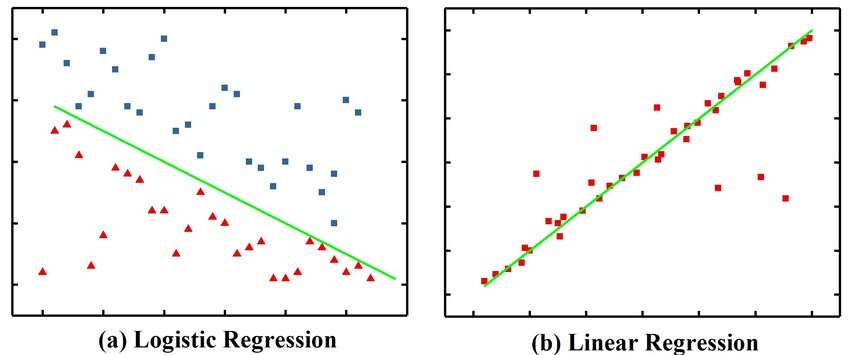

source:https://www.researchgate.net/figure/Logistic-regression-and-linear-regression_fig1_335786324

A logistic regression **(a)** has the goal of separating two or more classes based on specific variables (or features, in this case the dimensionality of our vectors). This algorithm is a linear algorithm, meaning that it can't solve a problem similar to the one on the next figure as there is no perfect boundary that can't separate the two classes:

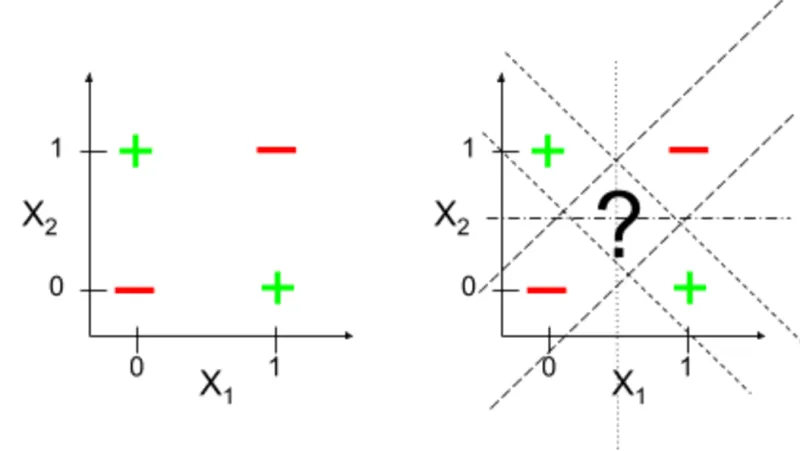

Even so, logistic regression is used widely due to it's simplicity, adaptability and explainability. But, how exactly is the model trained?

The model is trained (similarly to other algorithms) in machine learning using the concept of "error minimization". What do we want to do in this case? Minimize the error of our predictions (i.e. predicting that a review is positive when it is negative and vice-versa) - so our objective is to minimize this error during training based on "weights" that we give to the input variables. (similar to the example we've done with a Neural Network).
<br>
<br>
We start at an arbitrary point and then descend towards a minimum error based on changing the parameters. **Let's see this visually and imagining we just had one feature in our model:**

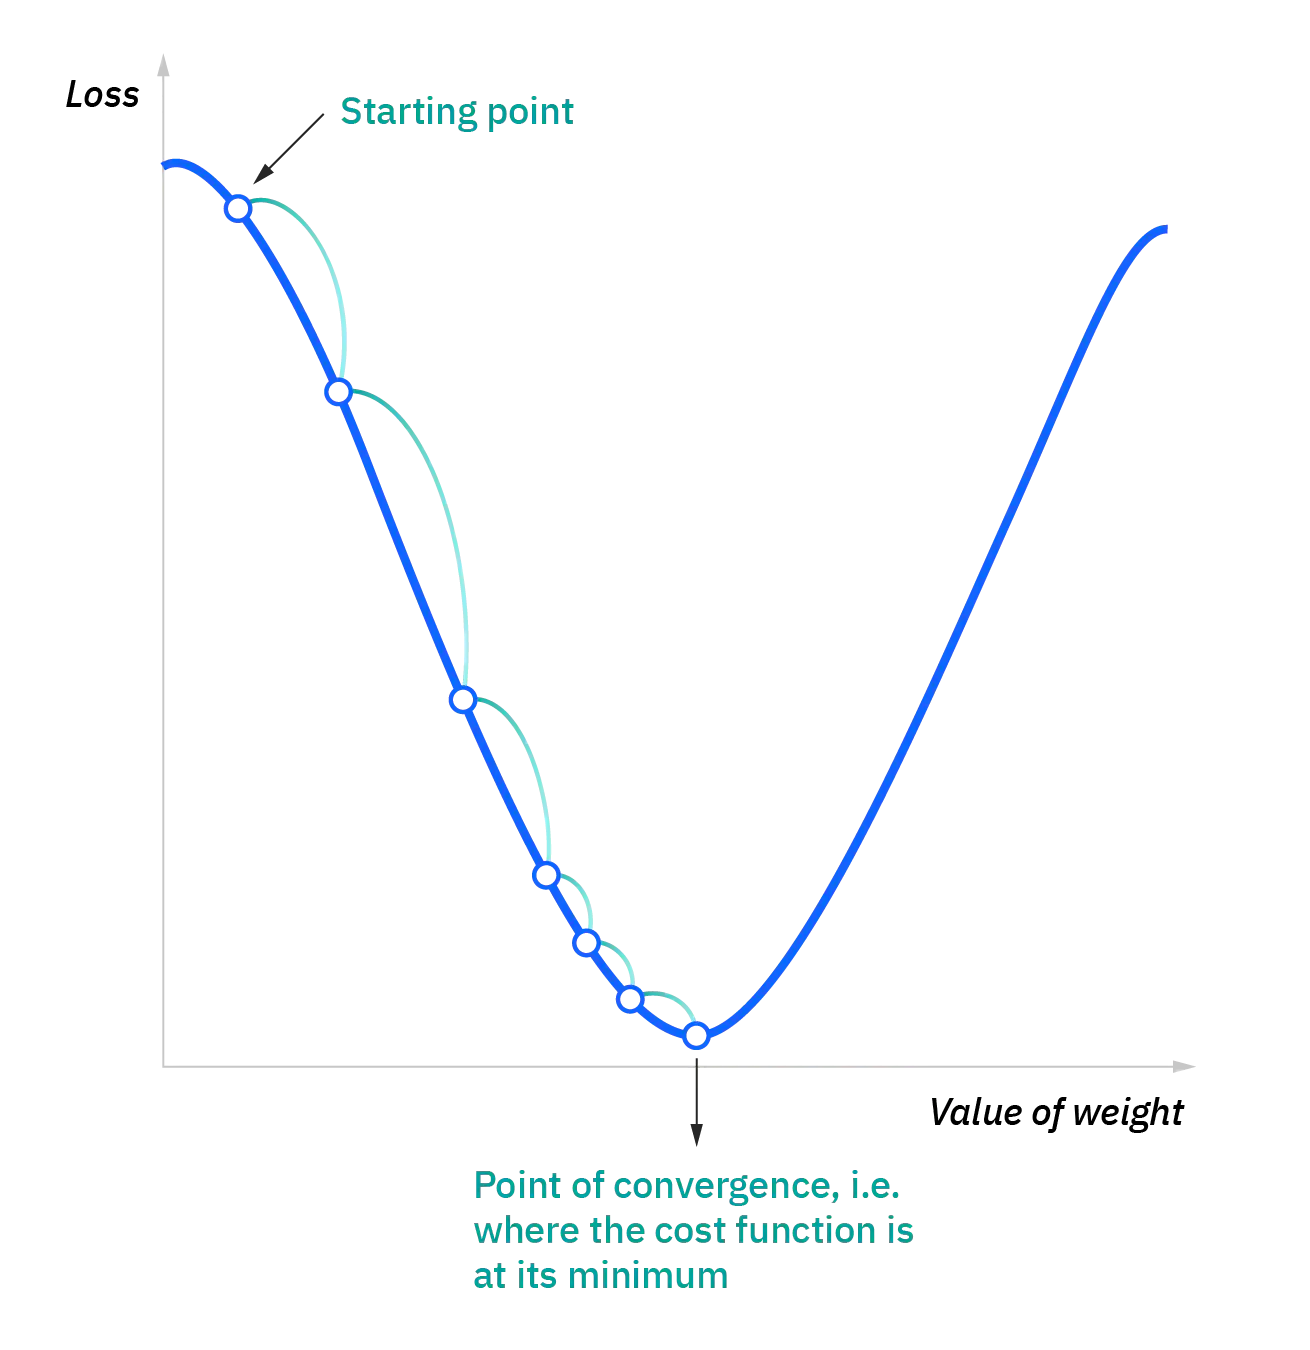

*source: https://www.ibm.com/cloud/learn/gradient-descent*

In the plot above consider the following:
- On the y-axis the "Loss" is our average error - in our case the difference between the target (1 or 0) and what our algorithm is predicting.
- On the x-axis imagine that the Value of Weight is the weight we are going to give the word `"worst"` in our model. This word be the only variable we will use in our first training example.
<br>


If you randomnly try different weights for the word `"worst"` in our reviews and take that weight into account to output the probability of a review being positive or not, we will have different error values depending on that weight. Let's test that, using our reviews! 

In [38]:
# Let's subset a single feature for our model - the column that states
# if the review contains the word worst or not
feature = X['worst']

In [39]:
feature.head(50)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     1
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
32    0
33    0
34    0
35    0
36    0
37    1
38    0
39    0
40    0
41    0
42    0
43    0
44    0
45    0
46    0
47    0
48    0
49    0
Name: worst, dtype: int64

From the first 50 reviews, only review number 21 contains the word `worst`.

Now, if I multiply the value of the feature by some arbitrary value we will have a new value. We will start to multiply our variable by 1.2 and this will be our first random weight.

In [40]:
feature_weight = feature*1.2

In [41]:
feature_weight.head(50)

0    0.00
1    0.00
2    0.00
3    0.00
4    0.00
5    0.00
6    0.00
7    1.20
8    0.00
9    0.00
10   0.00
11   0.00
12   0.00
13   0.00
14   0.00
15   0.00
16   0.00
17   0.00
18   0.00
19   0.00
20   0.00
21   0.00
22   0.00
23   0.00
24   0.00
25   0.00
26   0.00
27   0.00
28   0.00
29   0.00
30   0.00
31   0.00
32   0.00
33   0.00
34   0.00
35   0.00
36   0.00
37   1.20
38   0.00
39   0.00
40   0.00
41   0.00
42   0.00
43   0.00
44   0.00
45   0.00
46   0.00
47   0.00
48   0.00
49   0.00
Name: worst, dtype: float64

Notice that the feature weight now has values that range from 0 to 1.2 - but our target is between 0 and 1? If the resulting output of this simple model is 1.2 and we want to classify our target between 0 and 1 (Positive = 1 and Negative = 0), 1.2 is outside the boundary.
<br>
<br>
This is where we will use a concept we've already learn - the sigmoid function!

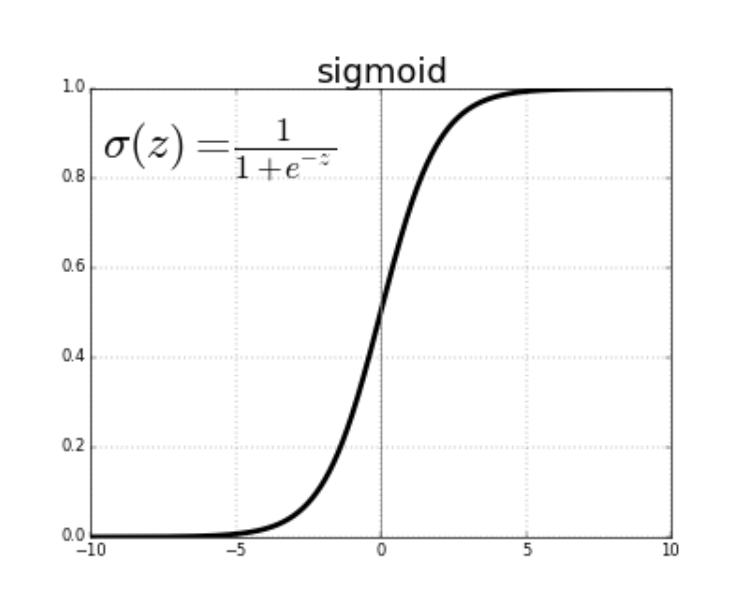

The sigmoid is a function that gets any value and positions it between 0 and 1. Notice how 0 on the input of the sigmoid will output 0.5 - this is basically a neutral position of the function. In our case, we would say that there is 50% chance that the review is negative and 50% chance that the review is positive.
<br>
<br>
*Note: Logistic regression does not output a pure probability but it is helpful to think that it is.*
<br>
<br>
Let's now pass our feature output value on the sigmoid function - we will need the `math` module here:

In [42]:
1/(1+math.e**(-feature_weight))

0      0.50
1      0.50
2      0.50
3      0.50
4      0.50
       ... 
1995   0.50
1996   0.77
1997   0.50
1998   0.50
1999   0.50
Name: worst, Length: 2000, dtype: float64

As we have a lot of 0's, and these 0's do not carry much information, only absence of the word - the majority of reviews will be labeled as neither positive nor negative (0.5).

We just extracted a proxy for the probability of a review being positive! Values next to 1 mean that that specific review has a higher probability of being positive. To simplify, we'll assume that every review that has a value of over 0.5 has a higher probability of being positive. Otherwise, we will say that the review is going to be negative:

In [43]:
model_output = 1/(1+math.e**(-feature_weight))

In [44]:
np.round(model_output).head(30)

0    0.00
1    0.00
2    0.00
3    0.00
4    0.00
5    0.00
6    0.00
7    1.00
8    0.00
9    0.00
10   0.00
11   0.00
12   0.00
13   0.00
14   0.00
15   0.00
16   0.00
17   0.00
18   0.00
19   0.00
20   0.00
21   0.00
22   0.00
23   0.00
24   0.00
25   0.00
26   0.00
27   0.00
28   0.00
29   0.00
Name: worst, dtype: float64

Now we can compare this output with the real values of positive and negative reviews:

In [45]:
predicted_target = np.round(model_output)

In [46]:
predicted_target==y

ValueError: ('Lengths must match to compare', (2000,), (2001,))

`False` means we are not predicting the correct target and `True` means that we are. 
<br>
<br>
Notice that as 0.5 is being assigned to 0 we are predicting more Negative reviews with the correct label just by randomness. In an ML model with a lot of variables, the probability that you will have an output exactly equals to 0.5 is quite low.

Let's compute our accuracy (remember the loss that we spoke on the gradient descent? It's related to accuracy, although we call it `categorical_crossentropy`)!

In [ ]:
(predicted_target==y).sum()/2000

0.425

With this simple model we are predicting 42.45% reviews correctly.

That's bad. Why? because if we predicted every review as negative we would get 50% correct labels. Let's then update our value from the weight in our model.
<br>
<br>
We know that the word **worst** is more relevant to negative reviews - so probably it would be a good idea to assign a negative weight (check the sigmoid function!) here.

In [ ]:
feature_weight_new_model = feature*-1.2
model_output_new_model = 1/(1+math.e**(-feature_weight_new_model))
predicted_target_new_model = np.round(model_output_new_model)

In [ ]:
(predicted_target_new_model==y).sum()/2000

0.5005

Ok, cool! We were able to improve our model just by tweaking the weight to -1.2. We have done a manually approach to gradient descent! Let's do a final experiment with two variables - the word **worst** and the word **truman**:

In [ ]:
features = X[['worst', 'truman']]

Now let's multiply worst by -1.2 and truman by 1.2:

In [ ]:
features['worst'] = features['worst']*-1.2
features['truman'] = features['truman']*1.2

In [ ]:
features

,worst,truman
0,-0.0,0.0
1,-0.0,0.0
2,-0.0,0.0
3,-0.0,0.0
4,-0.0,0.0
...,...,...
1996,-0.0,0.0
1997,-0.0,0.0
1998,-0.0,0.0
1999,-0.0,0.0


In [ ]:
features.sum(axis=1)

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
1996    0.0
1997    0.0
1998    0.0
1999    0.0
2000    0.0
Length: 2001, dtype: float64

How to pass two features to the sigmoid? By summing the weighted values!

In [ ]:
model_output_two_features = 1/(1+math.e**(-features.sum(axis=1)))

We have a new predicted probability:

In [ ]:
model_output_two_features

0       0.5
1       0.5
2       0.5
3       0.5
4       0.5
       ... 
1996    0.5
1997    0.5
1998    0.5
1999    0.5
2000    0.5
Length: 2001, dtype: float64

In [ ]:
(np.round(model_output_two_features)==y).sum()/2000

0.506

We've successfuly improved our classification with the new feature (although just a tiny bit)!

In [ ]:
X.shape

(2001, 31901)

Remember that we have about 31.901 features for our potential model, doing this manually would be near impossible. We can use the Logistic Regression function from the `sklearn` library to do this for us!

In [ ]:
X.columns

Index(['00', '000', '0009f', '000acr', '000aweek', '000foot', '000paltri',
       '007', '007esqu', '010',
       ...
       'zuehlk', 'zuko', 'zukovski', 'zulu', 'zundel', 'zurg', 'zweibel',
       'zwick', 'zwigoff', 'zyci'],
      dtype='object', length=31901)

With the `CountVectorizer`, we were able to use the logic behind the log-ratio to extract features that we knew would improve our algorithm (`truman` and `worst`). With the word vectors approach, we hope that the word vectors will have this information but hidden inside the 300-dimensional vector, but it's harder to interpret what each individual column will represent.

### 2.2 Training Process

Another important step that we should know is that we should never evaluate our trained algorithm on the same data that we have trained it on. This will lead to problems with our algorithm adapting "too well" to the training dataset and performing poorly on new data.
<br>
<br>
This is a really important concept known as **overfitting** - to guarantee that there is a low likelihood of this happening in our model, we have to evaluate our algorithm in a sample that is not going to be fed to the training process (and being utilized to improve the weights).

In real world projects and when we have more rows, we may do this with even more datasets that are not used during the training process.

<br> Let's then select 100 positive and 100 negative reviews that will be used just for evaluation. The idea is that we will test that the weights we've found are able to correctly guess the sentiment of these reviews without using them in the training process.

In [ ]:
X_test = pd.concat([X.iloc[0:100], X.iloc[-100:]], ignore_index=True)
y_test = np.append(y[0:100],y[-100:])

And now selecting our training set, which will contain 1801 reviews:

In [ ]:
X_train = X[100:len(X)-100]
y_train = y[100:len(y)-100]

Note that with our huge dimensional space we have more probability of overfitting our algorithm. Let's train our model with these features first:

In [ ]:
lm_count_vectorizer = LogisticRegression(random_state=1234)

In [ ]:
lm_count_vectorizer.fit(X_train, y_train)

LogisticRegression(random_state=1234)

Let's check the `accuracy` on our train_set first - we can use the predict method to predict using our trained model:

In [ ]:
y_pred = lm_count_vectorizer.predict(X_train)

In [ ]:
((y_pred == y_train).sum())/len(y_train)

1.0

Our accuracy is 100% on the training set. This is a result that is showing us that we are overfitting our hypothesis.  The weights we've found adjust perfectly to our training set and that is, generally, a bad sign.
<br>
<br>
As discussed, to really evaluate the performance of our algorithm, we have to check the accuracy in the test set. The rows that we left out of this training process and that mimic the real world that the algorithm should find. **This is one of the most common errors that data science rookies make: assuming that because your algorithm achieves 100% accuracy in the training set you have a good model.** 

In [ ]:
y_pred_test = lm_count_vectorizer.predict(X_test)

In [ ]:
(y_pred_test == y_test).sum()/len(y_test)

0.86

As you can see, our model behaves generally well, but in the test set it is able to achieve 87% accuracy. This is what we should expect if we put this model in production.
<br>
<br>
Having this difference in accuracy between training and test datasets is not optimum as it may lead to a quicker accuracy drift. We can reduce overfitting by:
* Reducing the number of features.
* Changing the type of model.
* Doing a technique called regularization.

Let's try the first two. To reduce the number of features, we can pick up our vectorizer with the document vectors and use that as `x_train`!

In [ ]:
X_train_2 = X_2[100:len(X_2)-100]
X_test_2 = np.vstack([X_2[0:100],X_2[-100:]])

In [ ]:
lm_wordvec = LogisticRegression(random_state=1234)

In [ ]:
lm_wordvec.fit(X_train_2, y_train)

LogisticRegression(random_state=1234)

In [ ]:
y_pred_wordvec = lm_wordvec.predict(X_train_2)

In [ ]:
((y_pred_wordvec == y_train).sum())/len(y_train)

0.8573014991671294

In [ ]:
y_pred_test_wordvec = lm_wordvec.predict(X_test_2)

In [ ]:
((y_pred_test_wordvec == y_test).sum())/len(y_test)

0.805

Another common way to evaluate the results of classification models is to use a `ConfusionMatrix`:

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred_test)

In [ ]:
pd.DataFrame(
    cm,
    columns = ['Predicted Positive', 'Predicted Negative'],
    index = ['Positive Reviews', 'Negative Reviews']
)

,Predicted Positive,Predicted Negative
Positive Reviews,84,16
Negative Reviews,23,77


Notice that, although our train and test set accuracies are lower with word vectors, the difference between training and test set is lower than in the solution with `CountVectorizer`. This will make your model a bit more stable when you want to productize it and use it with "real" new data.

In [ ]:
# Some metrics we can extract from the confusion matrix: 
TN, FP, FN, TP = cm[0][0], cm[0][1], cm[1][0], cm[1][1]

# Calculate Precision, Recall, and F1 Score
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1_score = 2 * (precision * recall) / (precision + recall)

# Display using .format()
print("Precision: {:.2f}".format(precision))
print("Recall: {:.2f}".format(recall))
print("F1 Score: {:.2f}".format(f1_score))

Precision: 0.83
Recall: 0.77
F1 Score: 0.80


### 2.3 Training Process using Naive Bayes Classifier

Let's see the performance of our model if we train a Naive Bayes Classifier:

In [ ]:
nb = MultinomialNB()
nb.fit(X_train, y_train)

MultinomialNB()

In [ ]:
y_pred_nb_train = nb.predict(X_train)
y_pred_nb = nb.predict(X_test)

In [ ]:
((y_pred_nb == y_test).sum())/len(y_test)

0.855

In [ ]:
((y_pred_nb_train == y_train).sum())/len(y_train)

0.9800111049416991

And checking the performance with Word2Vec vectorizer - `MultinomialNB` can't handle negative values so we need to use `GaussianNB`:

In [ ]:
nb_vec = GaussianNB()
nb_vec.fit(X_train_2, y_train)

GaussianNB()

In [ ]:
y_pred_gnb_train = nb_vec.predict(X_train_2)
y_pred_gnb = nb_vec.predict(X_test_2)

In [ ]:
((y_pred_gnb == y_test).sum())/len(y_test)

0.635

In [ ]:
((y_pred_gnb_train == y_train).sum())/len(y_train)

0.6490838423098279

Why such a low performance? GaussianNB assumes that there is a normal distribution on the features - we can't guarantee that with the Word2Vec weights!

In [ ]:
nb.predict_proba(X_test.iloc[5].values.reshape(1, -1))

array([[0.00, 1.00]])

# 3. Classifying New Reviews

Let's use some of the models we've developed to classify new reviews. In this part of the notebook, we'll use some reviews about recent movies that were not on the training base, and see how our models are able to classify the sentiment.

In [ ]:
new_review = """Interstellar is nothing short of a cinematic masterpiece. 
Christopher Nolan's foray into the vast expanse of the cosmos is both visually stunning 
and emotionally resonant. The film's grandiose depictions of distant galaxies and 
black holes are unparalleled, making viewers feel as though they are truly journeying 
through the stars alongside the film's intrepid astronauts. Yet, at its heart,
"Interstellar" remains a profoundly human story, exploring the unbreakable bonds 
of love and the lengths to which we will go to safeguard the future of our loved ones. 
Hans Zimmer's hauntingly beautiful score perfectly complements the film's visual splendor, 
evoking a sense of wonder and melancholy in equal measure. In an age of formulaic blockbusters, 
"Interstellar" stands out as a bold and thought-provoking epic that challenges, mesmerizes, 
and ultimately uplifts. A must-watch for all who believe in the boundless potential of 
the human spirit."""

**We need to use exactly the same pipeline (that we've done in the training process) for the new review!**

In [ ]:
def pipeline(review_to_process):
    
    review_preprocessed = remove_punct([review_to_process.lower()])
    tokenized_review = word_tokenize(review_preprocessed[0])
    stemmer = PorterStemmer()

    stemmed_review = [stemmer.stem(word) for word in tokenized_review]

    # We need to transform because we need to use the vocab from
    # the training process
    vectorized_review = cv.transform([' '.join(stemmed_review)])
    
    return vectorized_review

vectorized_review = pipeline(new_review)

In [ ]:
# Let's predict the sentiment
lm_count_vectorizer.predict_proba(vectorized_review)

array([[0.02, 0.98]])

On the left, we have the probability of the review having negative sentiment - on the right, we have the opposite, the probability that it is positive.

Our model is predicting that this review has 98% probability of being a positive review! Here, we've used the `LogisticRegression` with the `CountVectorizer`.

Let's see what happens when we have a neutral review:

In [ ]:
neutral_review = """Toy Story 3 continues Pixar's beloved franchise, taking our favorite toys on yet another adventure as they grapple with the inevitability of change and growing up. The animation remains top-notch, and the voice acting brings familiar warmth to these well-known characters. While the narrative hits many of the emotional beats one would expect, especially in its portrayal of the bond between toys and their owner, some may feel it treads familiar ground. It serves as a suitable sequel that fans of the series will appreciate, even if it doesn't quite capture the groundbreaking magic of its predecessors. Overall, a decent watch that adds another chapter to Woody, Buzz, and the gang's ongoing saga."""

In [ ]:
vectorized_review_neutral = pipeline(neutral_review)

In [ ]:
# Let's predict the sentiment
lm_count_vectorizer.predict_proba(vectorized_review_neutral)

array([[0.07, 0.93]])

Let's see what happens with a negative review:

In [ ]:
negative_review = '''
Christopher Nolan's ambitious space epic, "Interstellar", strives for the stars, but ultimately crash-lands into a black hole of convoluted storytelling. While it cannot be denied that the film boasts stellar visuals and some genuinely heart-pounding sequences, it's overshadowed by its attempts to intertwine quantum physics with human drama. The result? An overly complex narrative that often confuses more than it clarifies.

The film's runtime is bloated, meandering through subplots that could've been tightened or removed altogether. Nolan’s infatuation with thematic grandiosity detracts from the simplicity of a father-daughter relationship, which should've been the film's beating heart.

Matthew McConaughey delivers a commendable performance, but even he can't save the jumbled dialogue, some of which sounds like it was lifted directly from a physics textbook. Meanwhile, other characters are woefully underdeveloped, serving little more than exposition mouthpieces.

Hans Zimmer's score, though epic in places, is often so overbearing that it drowns out pivotal dialogue, making key moments feel more like a rock concert than a meaningful cinematic experience.

In the end, "Interstellar" could have been a thought-provoking exploration of space, time, and love. Instead, it feels like a missed opportunity, lost in its own labyrinthine ambitions.
'''

In [ ]:
vectorized_review_negative = pipeline(negative_review)

In [ ]:
# Let's predict the sentiment
lm_count_vectorizer.predict_proba(vectorized_review_negative)

array([[0.79, 0.21]])

In [ ]:
negative_wordvec = nlp(negative_review.lower()).vector

In [ ]:
# Let's predict the sentiment
lm_wordvec.predict_proba(negative_wordvec.reshape(1, -1))

array([[0.88, 0.12]])

And finally, a neutral example:

In [ ]:
neutral_review = """
"Interstellar" stands as one of Christopher Nolan's most ambitious undertakings. The film takes us on a grand journey through space, time, and the complexities of human emotions, presenting a mixed bag that will resonate differently for various viewers.

On one hand, its visuals are undeniably captivating. Nolan's depiction of outer space and the celestial bodies beyond our galaxy showcases the film's commitment to delivering a genuine spectacle. However, for every breathtaking shot, there seems to be a sequence that drags on a bit too long, leading to a somewhat uneven pacing.

The cast, led by Matthew McConaughey, delivers competent performances. Yet, the depth of their characters varies. While the central relationship between a father and his daughter is explored in depth, some supporting characters feel more like tools for exposition than fleshed-out individuals.

The soundtrack by Hans Zimmer is both a blessing and a curse. There are moments when it elevates the narrative, inducing goosebumps, and there are instances where it feels overwhelming, slightly overshadowing the dialogue.

In essence, "Interstellar" offers a lot to ponder and appreciate. But it equally provides moments that may leave you scratching your head or glancing at your watch. It's a cinematic experience that's neither groundbreaking nor forgettable—a journey worth taking, but with tempered expectations.
"""

In [ ]:
vectorized_review_neutral = pipeline(neutral_review)
neutral_wordvec = nlp(neutral_review.lower()).vector

In [ ]:
lm_count_vectorizer.predict_proba(vectorized_review_neutral)

array([[0.01, 0.99]])

In [ ]:
lm_wordvec.predict_proba(neutral_wordvec.reshape(1, -1))

array([[0.01, 0.99]])

Unfortunately, both models are not very good at targeting neutral reviews. Mostly, this happens because we don't have this target in the training data - if you want to explicitly add "neutral" review, it would be helpful to add that class of review to the training base so that the model was able to understand which words were important for those types of reviews.

In [47]:
import os

In [48]:
os.listdir('./data/pos/')

['cv839_21467.txt',
 'cv034_29647.txt',
 'cv908_16009.txt',
 'cv748_12786.txt',
 'cv253_10077.txt',
 'cv147_21193.txt',
 'cv962_9803.txt',
 'cv686_13900.txt',
 'cv410_24266.txt',
 'cv913_29252.txt',
 'cv695_21108.txt',
 'cv601_23453.txt',
 'cv490_17872.txt',
 'cv518_13331.txt',
 'cv157_29372.txt',
 'cv570_29082.txt',
 'cv289_6463.txt',
 'cv098_15435.txt',
 'cv656_24201.txt',
 'cv878_15694.txt',
 'cv172_11131.txt',
 'cv152_8736.txt',
 'cv762_13927.txt',
 'cv028_26746.txt',
 'cv756_22540.txt',
 'cv595_25335.txt',
 'cv701_14252.txt',
 'cv407_22637.txt',
 'cv794_15868.txt',
 'cv000_29590.txt',
 'cv375_9929.txt',
 'cv891_6385.txt',
 'cv198_18180.txt',
 'cv161_11425.txt',
 'cv440_15243.txt',
 'cv497_26980.txt',
 'cv090_0042.txt',
 'cv382_7897.txt',
 'cv383_13116.txt',
 'cv625_12440.txt',
 'cv234_20643.txt',
 'cv217_28842.txt',
 'cv545_12014.txt',
 'cv367_22792.txt',
 'cv209_29118.txt',
 'cv449_8785.txt',
 'cv579_11605.txt',
 'cv832_23275.txt',
 'cv785_22600.txt',
 'cv719_5713.txt',
 'cv510_2

In [49]:
positive_files = os.listdir('./data/pos/')[0:1000]
negative_files = os.listdir('./data/neg/')[0:1000]

In [50]:
def get_reviews(directory, list_of_files):
    files = []
    for file in list_of_files:
        f = open(directory + file, 'r')
        files.append(f.read())
        f.close()
    return files

In [51]:
positive_files_text = get_reviews('./data/pos/',positive_files)
negative_files_text = get_reviews('./data/neg/',negative_files)


In [52]:
len(positive_files_text)

1000

In [53]:
print(positive_files_text[0])

assume nothing . 
the phrase is perhaps one of the most used of the 1990's , as first impressions and rumors are hardly ever what they seem to be . 
the phrase especially goes for oscar novak , an architect who is the main focus of three to tango , a delightful , funny romantic comedy about assumptions and being yourself . 
novak ( matthew perry ) , a shy , clumsy , chicago based architect , along with openly gay partner , peter steinberg ( oliver platt ) , fights for projects day in and day out . 
one of these is the job of restoring a popular building for charles newman ( dylan mcdermott ) , a rich , well-known businessman . 
charles immediately takes a liking to oscar , as he enjoys his personality and sense of humor . 
seeing oscar as someone he could trust , charles asks him to watch his girlfriend , an unpredictable , adventurous girl named amy post ( neve campbell ) , who makes a living by blowing glass . 
charles wants to know who she talks to , what she does , and where she go

In [54]:
import string

In [55]:
## Preprocess text
positive_files_text = [text.lower() for text in positive_files_text]
negative_files_text = [text.lower() for text in negative_files_text]

In [56]:
### remove punctuation

In [57]:
positive_files_text = [
    text.translate(str.maketrans('', '', string.punctuation)) for text in positive_files_text
]
negative_files_text = [
    text.translate(str.maketrans('', '', string.punctuation)) for text in negative_files_text
]

In [58]:
print([positive_files_text[0]])

['assume nothing  \nthe phrase is perhaps one of the most used of the 1990s  as first impressions and rumors are hardly ever what they seem to be  \nthe phrase especially goes for oscar novak  an architect who is the main focus of three to tango  a delightful  funny romantic comedy about assumptions and being yourself  \nnovak  matthew perry   a shy  clumsy  chicago based architect  along with openly gay partner  peter steinberg  oliver platt   fights for projects day in and day out  \none of these is the job of restoring a popular building for charles newman  dylan mcdermott   a rich  wellknown businessman  \ncharles immediately takes a liking to oscar  as he enjoys his personality and sense of humor  \nseeing oscar as someone he could trust  charles asks him to watch his girlfriend  an unpredictable  adventurous girl named amy post  neve campbell   who makes a living by blowing glass  \ncharles wants to know who she talks to  what she does  and where she goes  \nthe point  \nto make 

In [59]:
### Remove stopwords

In [60]:
from nltk.corpus import stopwords
sw = stopwords.words('english')
sw

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [61]:
from nltk.tokenize import word_tokenize


In [62]:
positive_files_token = [word_tokenize(text) for text in positive_files_text]
negative_files_token = [word_tokenize(text) for text in negative_files_text]

In [63]:
positive_files_token[0]

['assume',
 'nothing',
 'the',
 'phrase',
 'is',
 'perhaps',
 'one',
 'of',
 'the',
 'most',
 'used',
 'of',
 'the',
 '1990s',
 'as',
 'first',
 'impressions',
 'and',
 'rumors',
 'are',
 'hardly',
 'ever',
 'what',
 'they',
 'seem',
 'to',
 'be',
 'the',
 'phrase',
 'especially',
 'goes',
 'for',
 'oscar',
 'novak',
 'an',
 'architect',
 'who',
 'is',
 'the',
 'main',
 'focus',
 'of',
 'three',
 'to',
 'tango',
 'a',
 'delightful',
 'funny',
 'romantic',
 'comedy',
 'about',
 'assumptions',
 'and',
 'being',
 'yourself',
 'novak',
 'matthew',
 'perry',
 'a',
 'shy',
 'clumsy',
 'chicago',
 'based',
 'architect',
 'along',
 'with',
 'openly',
 'gay',
 'partner',
 'peter',
 'steinberg',
 'oliver',
 'platt',
 'fights',
 'for',
 'projects',
 'day',
 'in',
 'and',
 'day',
 'out',
 'one',
 'of',
 'these',
 'is',
 'the',
 'job',
 'of',
 'restoring',
 'a',
 'popular',
 'building',
 'for',
 'charles',
 'newman',
 'dylan',
 'mcdermott',
 'a',
 'rich',
 'wellknown',
 'businessman',
 'charles',
 

In [64]:
def remove_stop_words(tokenized_list,stop_words_file):
    list_files_no_stop = []
    for file in tokenized_list:
        review_no_stop_words = []
        for word in file:
            if word not in stop_words_file:
                review_no_stop_words.append(word)
        list_files_no_stop.append(review_no_stop_words)
    return list_files_no_stop

In [65]:
positive_files_token_no_sw = remove_stop_words(positive_files_token,sw)
negative_files_token_no_sw = remove_stop_words(negative_files_token,sw)

In [66]:
' '.join(positive_files_token_no_sw[0])

'assume nothing phrase perhaps one used 1990s first impressions rumors hardly ever seem phrase especially goes oscar novak architect main focus three tango delightful funny romantic comedy assumptions novak matthew perry shy clumsy chicago based architect along openly gay partner peter steinberg oliver platt fights projects day day one job restoring popular building charles newman dylan mcdermott rich wellknown businessman charles immediately takes liking oscar enjoys personality sense humor seeing oscar someone could trust charles asks watch girlfriend unpredictable adventurous girl named amy post neve campbell makes living blowing glass charles wants know talks goes point make sure shes seeing someone else course oscar gladly takes job meets amy art show sparks fly two get go oscar feels found one meant content idea amy well another popular phrase 90s good things must come end stays true oscar well charles walks amy oscar drink one night oscar amy become great friends doesnt seem min

In [67]:
positive_files_text[0]

'assume nothing  \nthe phrase is perhaps one of the most used of the 1990s  as first impressions and rumors are hardly ever what they seem to be  \nthe phrase especially goes for oscar novak  an architect who is the main focus of three to tango  a delightful  funny romantic comedy about assumptions and being yourself  \nnovak  matthew perry   a shy  clumsy  chicago based architect  along with openly gay partner  peter steinberg  oliver platt   fights for projects day in and day out  \none of these is the job of restoring a popular building for charles newman  dylan mcdermott   a rich  wellknown businessman  \ncharles immediately takes a liking to oscar  as he enjoys his personality and sense of humor  \nseeing oscar as someone he could trust  charles asks him to watch his girlfriend  an unpredictable  adventurous girl named amy post  neve campbell   who makes a living by blowing glass  \ncharles wants to know who she talks to  what she does  and where she goes  \nthe point  \nto make s

In [68]:
positive_files_token_no_sw[0]

['assume',
 'nothing',
 'phrase',
 'perhaps',
 'one',
 'used',
 '1990s',
 'first',
 'impressions',
 'rumors',
 'hardly',
 'ever',
 'seem',
 'phrase',
 'especially',
 'goes',
 'oscar',
 'novak',
 'architect',
 'main',
 'focus',
 'three',
 'tango',
 'delightful',
 'funny',
 'romantic',
 'comedy',
 'assumptions',
 'novak',
 'matthew',
 'perry',
 'shy',
 'clumsy',
 'chicago',
 'based',
 'architect',
 'along',
 'openly',
 'gay',
 'partner',
 'peter',
 'steinberg',
 'oliver',
 'platt',
 'fights',
 'projects',
 'day',
 'day',
 'one',
 'job',
 'restoring',
 'popular',
 'building',
 'charles',
 'newman',
 'dylan',
 'mcdermott',
 'rich',
 'wellknown',
 'businessman',
 'charles',
 'immediately',
 'takes',
 'liking',
 'oscar',
 'enjoys',
 'personality',
 'sense',
 'humor',
 'seeing',
 'oscar',
 'someone',
 'could',
 'trust',
 'charles',
 'asks',
 'watch',
 'girlfriend',
 'unpredictable',
 'adventurous',
 'girl',
 'named',
 'amy',
 'post',
 'neve',
 'campbell',
 'makes',
 'living',
 'blowing',
 'gl

In [69]:
flat_list_positive = [word for review in positive_files_token_no_sw for word in review]
flat_list_negative = [word for review in negative_files_token_no_sw for word in review]

In [70]:
len(flat_list_positive)

375030

In [71]:
import nltk

In [72]:
flat_list_positive[0:10]

['assume',
 'nothing',
 'phrase',
 'perhaps',
 'one',
 'used',
 '1990s',
 'first',
 'impressions',
 'rumors']

In [73]:
nltk.FreqDist(flat_list_positive).most_common(30)

[('film', 4866),
 ('one', 2904),
 ('movie', 2392),
 ('like', 1718),
 ('story', 1215),
 ('also', 1200),
 ('films', 1199),
 ('good', 1193),
 ('even', 1174),
 ('time', 1171),
 ('characters', 1038),
 ('much', 1027),
 ('character', 1013),
 ('would', 993),
 ('life', 984),
 ('well', 968),
 ('first', 963),
 ('two', 960),
 ('see', 954),
 ('way', 915),
 ('get', 884),
 ('best', 809),
 ('many', 780),
 ('really', 776),
 ('make', 772),
 ('little', 770),
 ('people', 769),
 ('great', 745),
 ('movies', 734),
 ('new', 718)]

In [74]:
nltk.FreqDist(flat_list_negative).most_common(30)

[('film', 3994),
 ('movie', 3048),
 ('one', 2617),
 ('like', 1835),
 ('even', 1381),
 ('good', 1127),
 ('time', 1112),
 ('would', 1049),
 ('get', 1037),
 ('bad', 1019),
 ('much', 997),
 ('characters', 909),
 ('films', 903),
 ('story', 903),
 ('character', 893),
 ('plot', 876),
 ('two', 865),
 ('make', 818),
 ('first', 805),
 ('really', 787),
 ('see', 776),
 ('could', 768),
 ('also', 765),
 ('way', 753),
 ('well', 726),
 ('little', 721),
 ('movies', 682),
 ('dont', 672),
 ('doesnt', 670),
 ('scene', 658)]

In [75]:
nltk.FreqDist(flat_list_positive).values()

dict_values([23, 308, 16, 263, 2904, 174, 18, 963, 3, 12, 55, 399, 303, 292, 309, 149, 5, 5, 202, 82, 336, 8, 46, 386, 130, 389, 2, 53, 7, 20, 14, 29, 204, 281, 10, 70, 42, 128, 1, 45, 19, 32, 21, 342, 347, 4, 103, 60, 65, 18, 10, 8, 117, 14, 17, 91, 396, 14, 15, 55, 323, 197, 190, 163, 627, 35, 76, 316, 91, 22, 10, 189, 197, 37, 11, 31, 52, 561, 129, 14, 25, 239, 569, 23, 299, 772, 261, 186, 158, 314, 4, 117, 120, 362, 15, 34, 960, 884, 544, 121, 216, 33, 41, 166, 968, 559, 41, 1193, 447, 317, 411, 520, 23, 269, 27, 14, 216, 306, 745, 255, 597, 243, 64, 571, 39, 78, 170, 70, 35, 113, 8, 29, 77, 120, 2, 3, 48, 105, 7, 24, 225, 83, 1, 184, 242, 380, 993, 388, 7, 406, 51, 3, 127, 5, 46, 95, 1013, 2, 127, 178, 13, 15, 18, 37, 147, 260, 22, 164, 100, 21, 417, 321, 165, 954, 75, 252, 2392, 400, 149, 88, 197, 16, 88, 25, 13, 159, 42, 241, 50, 82, 149, 9, 645, 156, 95, 42, 113, 141, 43, 218, 717, 80, 101, 143, 24, 67, 715, 31, 320, 28, 16, 158, 36, 37, 162, 65, 1, 24, 20, 8, 39, 292, 14, 4866

In [76]:
import pandas as pd

In [77]:
positive_freq = pd.DataFrame(
    nltk.FreqDist(flat_list_positive).values(),
    index = nltk.FreqDist(flat_list_positive).keys(),
    columns = ['word_count_positive']
)
negative_freq = pd.DataFrame(
    nltk.FreqDist(flat_list_negative).values(),
    index = nltk.FreqDist(flat_list_negative).keys(),
    columns = ['word_count_negative']
)
word_sentiment = positive_freq.join(negative_freq).fillna(0)
word_sentiment

,word_count_positive,word_count_negative
assume,23,27.00
nothing,308,492.00
phrase,16,11.00
perhaps,263,195.00
one,2904,2617.00
...,...,...
piled,1,2.00
lifeforce,1,0.00
hunches,1,0.00
junichiro,1,0.00


In [78]:
import numpy as np

In [79]:
word_sentiment['ratio'] = np.log(
    word_sentiment.word_count_positive/word_sentiment.word_count_negative
)

In [80]:
word_sentiment_filtered = word_sentiment.loc[
    (word_sentiment.word_count_positive > 0) & (word_sentiment.word_count_negative > 0) &
    (word_sentiment.word_count_positive + word_sentiment.word_count_negative > 49)
]

In [81]:
word_sentiment_filtered.sort_values(by='ratio', ascending=False).head(20)

,word_count_positive,word_count_negative,ratio
mulan,78,1.00,4.36
flynt,62,1.00,4.13
damon,65,4.00,2.79
outstanding,69,5.00,2.62
scorsese,46,4.00,2.44
truman,121,11.00,2.40
finest,50,5.00,2.30
derek,50,6.00,2.12
era,63,8.00,2.06
jedi,69,9.00,2.04


In [82]:
word_sentiment_filtered.sort_values(by='ratio', ascending=True).head(20)

,word_count_positive,word_count_negative,ratio
seagal,1,63.00,-4.14
wrestling,5,51.00,-2.32
godzilla,14,116.00,-2.11
spawn,10,65.00,-1.87
wasted,16,101.00,-1.84
lame,15,90.00,-1.79
poorly,12,70.00,-1.76
waste,22,121.00,-1.70
worst,48,259.00,-1.69
ridiculous,22,117.00,-1.67


In [83]:
from nltk.stem import SnowballStemmer
snowball = SnowballStemmer("english")

In [84]:
def stem_sentence(tokenized_sentence,stemmer):
    stemmed_sent = []
    for word in tokenized_sentence:
        stemmed_word = stemmer.stem(word)
        stemmed_sent.append(stemmed_word)
    return stemmed_sent

In [85]:
stem_sentence(positive_files_token_no_sw[0],snowball)

['assum',
 'noth',
 'phrase',
 'perhap',
 'one',
 'use',
 '1990s',
 'first',
 'impress',
 'rumor',
 'hard',
 'ever',
 'seem',
 'phrase',
 'especi',
 'goe',
 'oscar',
 'novak',
 'architect',
 'main',
 'focus',
 'three',
 'tango',
 'delight',
 'funni',
 'romant',
 'comedi',
 'assumpt',
 'novak',
 'matthew',
 'perri',
 'shi',
 'clumsi',
 'chicago',
 'base',
 'architect',
 'along',
 'open',
 'gay',
 'partner',
 'peter',
 'steinberg',
 'oliv',
 'platt',
 'fight',
 'project',
 'day',
 'day',
 'one',
 'job',
 'restor',
 'popular',
 'build',
 'charl',
 'newman',
 'dylan',
 'mcdermott',
 'rich',
 'wellknown',
 'businessman',
 'charl',
 'immedi',
 'take',
 'like',
 'oscar',
 'enjoy',
 'person',
 'sens',
 'humor',
 'see',
 'oscar',
 'someon',
 'could',
 'trust',
 'charl',
 'ask',
 'watch',
 'girlfriend',
 'unpredict',
 'adventur',
 'girl',
 'name',
 'ami',
 'post',
 'neve',
 'campbel',
 'make',
 'live',
 'blow',
 'glass',
 'charl',
 'want',
 'know',
 'talk',
 'goe',
 'point',
 'make',
 'sure',
 '

In [86]:
stemmed_positive_files = []
for review in positive_files_token_no_sw:
    stemmed_review = stem_sentence(review,snowball)
    stemmed_review = ' '.join(stemmed_review)
    stemmed_positive_files.append(stemmed_review)

stemmed_negative_files = []
for review in negative_files_token_no_sw:
    stemmed_review = stem_sentence(review,snowball)
    stemmed_review = ' '.join(stemmed_review)
    stemmed_negative_files.append(stemmed_review)

In [87]:
stemmed_positive_files[0]

'assum noth phrase perhap one use 1990s first impress rumor hard ever seem phrase especi goe oscar novak architect main focus three tango delight funni romant comedi assumpt novak matthew perri shi clumsi chicago base architect along open gay partner peter steinberg oliv platt fight project day day one job restor popular build charl newman dylan mcdermott rich wellknown businessman charl immedi take like oscar enjoy person sens humor see oscar someon could trust charl ask watch girlfriend unpredict adventur girl name ami post neve campbel make live blow glass charl want know talk goe point make sure shes see someon els cours oscar glad take job meet ami art show spark fli two get go oscar feel found one meant content idea ami well anoth popular phrase 90s good thing must come end stay true oscar well charl walk ami oscar drink one night oscar ami becom great friend doesnt seem mind think oscar gay hes afraid share either oscar stand shock word swear werent gay oscar id kill mutter flam

In [88]:
len(stemmed_positive_files)

1000

In [89]:
len(stemmed_negative_files)

1000

In [90]:
stemmed_negative_files = pd.DataFrame(stemmed_negative_files,columns=['sentence'])
stemmed_positive_files = pd.DataFrame(stemmed_positive_files,columns=['sentence'])

In [91]:
stemmed_negative_files.head(10)

,sentence
0,bad bad bad one word seem pretti much sum beyo...
1,isnt ultim sign movi cinemat ineptitud cant th...
2,gordi movi 90minutelong sesam street skit bad ...
3,disconnect phone line dont accept charg anyth ...
4,robert forster found famous appear jacki brown...
5,first review post newsgroup kind feel like say...
6,lake placid mark yet anoth entri seri predat p...
7,main problem martin lawrenc pet project thin l...
8,educ know happi star sylvia chang teresa hu hs...
9,jet li bust onto american action movi scene st...


In [92]:
from sklearn.feature_extraction.text import CountVectorizer

In [93]:
cv = CountVectorizer(binary=True, min_df = 0.005)

# DataFrame.append was removed in pandas 2.0 -- use pd.concat instead
full_reviews = pd.concat(
    [stemmed_positive_files, stemmed_negative_files], ignore_index=True
)

In [94]:
X_full = pd.DataFrame(
    cv.fit_transform(full_reviews.sentence).todense(),
    columns=cv.get_feature_names_out()
)

In [95]:
X_full.head(10)

,000,10,100,1000,101,1010,11,12,13,13th,...,zane,zani,zellweg,zero,zest,zetajon,zinger,zombi,zone,zoom
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
2,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [96]:
X_full.shape

(2000, 6213)

In [97]:
X_full['worst']

0       0
1       0
2       0
3       0
4       0
       ..
1995    0
1996    1
1997    0
1998    0
1999    0
Name: worst, Length: 2000, dtype: int64

In [98]:
positive_files_text[7] # should have word 'worst'

'  the fighting sullivans  contains a major plot development in the last ten minutes that every movie guide has seen fit to give away  \nthere was no dramatic tension for me while watching the film  as i knew exactly what was going to happen  \nand thats the worst thing that can happen before viewing a movie  \nbecause of this  i will tread lightly so i dont ruin it for anyone reading this review  and it would be very advisable to avoid all other material regarding this film until after you have seen it  \n  the fighting sullivans  revolves around a family that consists of a mother  father  sister  and five brothers  \nthe brothers are very close  despite the occasional disagreement  \nthey are inseperable  and never stray from one another  \ntheir friendship and loyalty is the foundation of this picture  \nthe first half of the movie follows the brothers as young children  and their various adventures  \nwhen four of them get into a fight with some local boys  the youngest sullivan  w

In [99]:
y = np.append(np.ones(1000),np.zeros(1000))

In [100]:
pd.DataFrame(y, columns=['target_sentiment'])

,target_sentiment
0,1.00
1,1.00
2,1.00
3,1.00
4,1.00
...,...
1995,0.00
1996,0.00
1997,0.00
1998,0.00


In [101]:
X_full['worst']*1.2

0      0.00
1      0.00
2      0.00
3      0.00
4      0.00
       ... 
1995   0.00
1996   1.20
1997   0.00
1998   0.00
1999   0.00
Name: worst, Length: 2000, dtype: float64

In [102]:
experiment_1 = X_full['worst']*1.2
import math
(1/(1+math.e**-experiment_1)).head(30)

0    0.50
1    0.50
2    0.50
3    0.50
4    0.50
5    0.50
6    0.50
7    0.77
8    0.50
9    0.50
10   0.50
11   0.50
12   0.50
13   0.50
14   0.50
15   0.50
16   0.50
17   0.50
18   0.50
19   0.50
20   0.50
21   0.50
22   0.50
23   0.50
24   0.50
25   0.50
26   0.50
27   0.50
28   0.50
29   0.50
Name: worst, dtype: float64

In [103]:
experiment_1 = X_full['worst']*1.2
import math
result = 1/(1+math.e**-experiment_1)
result

0      0.50
1      0.50
2      0.50
3      0.50
4      0.50
       ... 
1995   0.50
1996   0.77
1997   0.50
1998   0.50
1999   0.50
Name: worst, Length: 2000, dtype: float64

In [104]:
y_pred = np.where(result>0.5,1,0)[0:30]
y_pred

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0])

In [105]:
y_pred = np.where(result>0.5,1,0)
y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [106]:
y

array([1.00, 1.00, 1.00, ..., 0.00, 0.00, 0.00])

In [107]:
y_pred[0:30]

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0])

In [108]:
y[0:30]

array([1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00,
       1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00])

In [109]:
y==y_pred

array([False, False, False, ...,  True,  True,  True])

In [110]:
(y==y_pred).sum()/2000 # Accuracy

np.float64(0.4245)

In [111]:
experiment_2 = X_full['worst']*-1.2
result_2 = 1/(1+math.e**-experiment_2)
y_pred_2 = np.where(result_2>0.5,1,0)
(y==y_pred_2).sum()/2000 # Accuracy

np.float64(0.5)

In [112]:
experiment_3 = X_full['worst']*-1.2+X_full['damon']*2
result_3 = 1/(1+math.e**-experiment_3)
y_pred_3 = np.where(result_3>0.5,1,0)
(y==y_pred_3).sum()/2000 # Accuracy

np.float64(0.5115)

In [113]:
X_test = pd.concat([X_full[:50], X_full[1950:]])
y_test = np.append(y[:50], y[1950:])

In [114]:
X_test.shape

(100, 6213)

In [115]:
y_test.shape

(100,)

In [116]:
y_test.sum()

np.float64(50.0)

In [117]:
X_train = X_full[50:1950]
y_train = y[50:1950]

In [118]:
X_train.shape

(1900, 6213)

In [119]:
y_train.shape

(1900,)

In [120]:
from sklearn.linear_model import LogisticRegression

In [121]:
logit_reg = LogisticRegression()

In [122]:
logit_reg

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [123]:
logit_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [124]:
y_new = logit_reg.predict(X_train)
y_new

array([1.00, 1.00, 1.00, ..., 0.00, 0.00, 0.00])

In [125]:
y

array([1.00, 1.00, 1.00, ..., 0.00, 0.00, 0.00])

In [126]:
from sklearn.metrics import accuracy_score

In [127]:
accuracy_score(y_train,y_new)

1.0

In [128]:
y_pred_test = logit_reg.predict(X_test)

In [129]:
accuracy_score(y_test, y_pred_test)

0.88

In [130]:
logit_reg_regul = LogisticRegression(C=0.001, penalty='l2')

In [131]:
logit_reg_regul.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.001
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver be

In [132]:
y_new = logit_reg_regul.predict(X_train)

In [133]:
accuracy_score(y_train,y_new)

0.888421052631579

In [134]:
y_pred_test = logit_reg_regul.predict(X_test)
accuracy_score(y_test, y_pred_test)

0.84

In [135]:
logit_reg_regul.coef_

array([[0.00, -0.01, 0.00, ..., -0.00, -0.00, -0.00]])

In [136]:
weights = pd.DataFrame(logit_reg_regul.coef_.T,columns=['weight_regression'], index=X_test.columns)
weights.sort_values(by='weight_regression',ascending=False)

,weight_regression
perfect,0.05
life,0.05
also,0.05
perform,0.04
great,0.04
...,...
plot,-0.05
worst,-0.06
bore,-0.06
wast,-0.06


In [137]:
weights.sort_values(by='weight_regression',ascending=True).head(40)

,weight_regression
bad,-0.09
wast,-0.06
bore,-0.06
worst,-0.06
plot,-0.05
noth,-0.05
stupid,-0.05
suppos,-0.05
script,-0.04
poor,-0.04


In [138]:
sentence_example = "I hate this, this movie was really awful, I never want to see it again"

In [139]:
def pass_sentence_pipeline(sentence, stop_words,stem_object,cv_object):
    sentence = sentence.translate(str.maketrans('', '', string.punctuation))
    sentence = [word for word in word_tokenize(sentence.lower()) if word not in stop_words]
    sentence_tokens = [stem_object.stem(word) for word in sentence]
    binary_sentence_vec = cv_object.transform(pd.Series(' '.join(sentence_tokens)))
    return binary_sentence_vec.toarray()

In [140]:
my_example_to_predict = pass_sentence_pipeline(sentence_example,sw,snowball,cv)
my_example_to_predict

array([[0, 0, 0, ..., 0, 0, 0]])

In [141]:
logit_reg_regul.predict_proba(my_example_to_predict)

array([[0.57, 0.43]])

probability to get negative review is 57% and to get positive is 43%